Mean reprojection error: 0.531 px


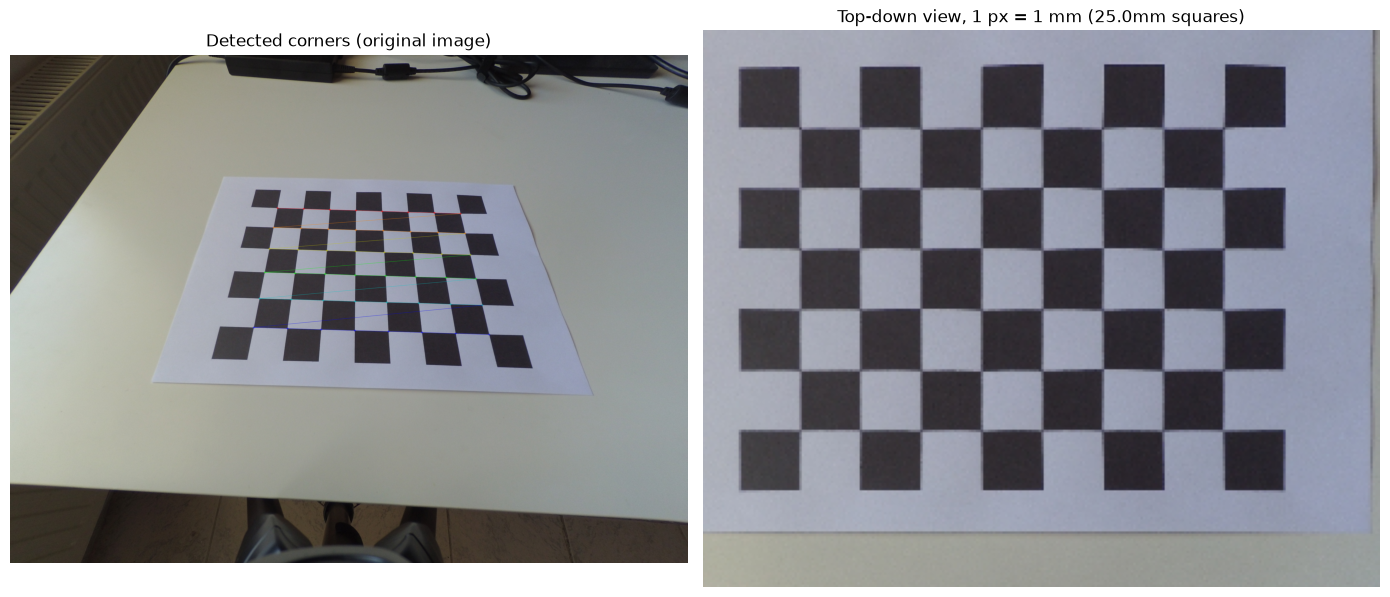

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "frame_4.jpg"

# Board spec: 8x6 SQUARES, 25 mm each.
# OpenCV's findChessboardCorners wants INNER corners, i.e. (squares - 1)
SQUARES_X, SQUARES_Y = 9, 7
SQUARE_SIZE_MM = 25.0
PATTERN_SIZE = (SQUARES_X - 1, SQUARES_Y - 1)  # (7, 5) inner corners

# --- Load image ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# --- Detect chessboard inner corners ---
ret, corners = cv2.findChessboardCorners(
    gray, PATTERN_SIZE,
    flags=cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE
)
if not ret:
    raise RuntimeError(
        f"Chessboard {PATTERN_SIZE} not found. Check SQUARES_X/SQUARES_Y "
        f"match the physical board, and that it's fully visible/unoccluded."
    )

# Sub-pixel refinement — turns the coarse corner guess into a precise one
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)

# --- Build the matching real-world (mm) coordinates for each inner corner ---
# Corner (i, j) sits at (i * SQUARE_SIZE_MM, j * SQUARE_SIZE_MM) on the board plane (z=0)
objp = np.zeros((PATTERN_SIZE[0] * PATTERN_SIZE[1], 2), dtype=np.float32)
objp[:, :2] = np.mgrid[0:PATTERN_SIZE[0], 0:PATTERN_SIZE[1]].T.reshape(-1, 2) * SQUARE_SIZE_MM

img_points = corners.reshape(-1, 2)

# --- Homography: image pixels <-> board-plane mm coordinates ---
# This is what "calibrates to the plane" — a single-image planar mapping
# (not a full 3D camera calibration, which needs multiple views/poses).
H, mask = cv2.findHomography(img_points, objp, method=0)
H_inv = np.linalg.inv(H)  # mm -> pixels, useful for drawing back onto the image


def pixel_to_mm(u, v):
    """Convert an image pixel coordinate to real-world mm on the board plane."""
    pt = np.array([u, v, 1.0])
    mm = H @ pt
    mm /= mm[2]
    return mm[0], mm[1]


def mm_to_pixel(x_mm, y_mm):
    """Convert a real-world mm coordinate on the board plane back to image pixels."""
    pt = np.array([x_mm, y_mm, 1.0])
    px = H_inv @ pt
    px /= px[2]
    return px[0], px[1]


# --- Sanity check: reproject objp through H_inv and compare to detected corners ---
reprojected = cv2.perspectiveTransform(objp.reshape(-1, 1, 2), H_inv).reshape(-1, 2)
reproj_error = np.linalg.norm(reprojected - img_points, axis=1).mean()
print(f"Mean reprojection error: {reproj_error:.3f} px")

# --- Warp the whole image to a top-down metric view (1 px = 1 mm) ---
board_w_mm = (SQUARES_X - 1) * SQUARE_SIZE_MM
board_h_mm = (SQUARES_Y - 1) * SQUARE_SIZE_MM
margin_mm = 40  # extra border so objects near the board edge aren't clipped
out_w = int(board_w_mm + 2 * margin_mm)
out_h = int(board_h_mm + 2 * margin_mm)

# shift so the board's top-left corner lands at (margin, margin) in the output,
# and keep the same mm/px scale (1:1) — i.e. no extra scaling needed since objp is already in mm
shift = np.array([
    [1, 0, margin_mm],
    [0, 1, margin_mm],
    [0, 0, 1]
], dtype=np.float64)
H_topdown = shift @ H  # image pixels -> shifted mm plane

warped = cv2.warpPerspective(img, H_topdown, (out_w, out_h))

# --- Visualize ---
vis = img.copy()
cv2.drawChessboardCorners(vis, PATTERN_SIZE, corners, ret)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
axes[0].set_title("Detected corners (original image)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Top-down view, 1 px = 1 mm ({SQUARE_SIZE_MM}mm squares)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Mean reprojection error: 0.531 px
Saved calibration to plane_calibration.npz


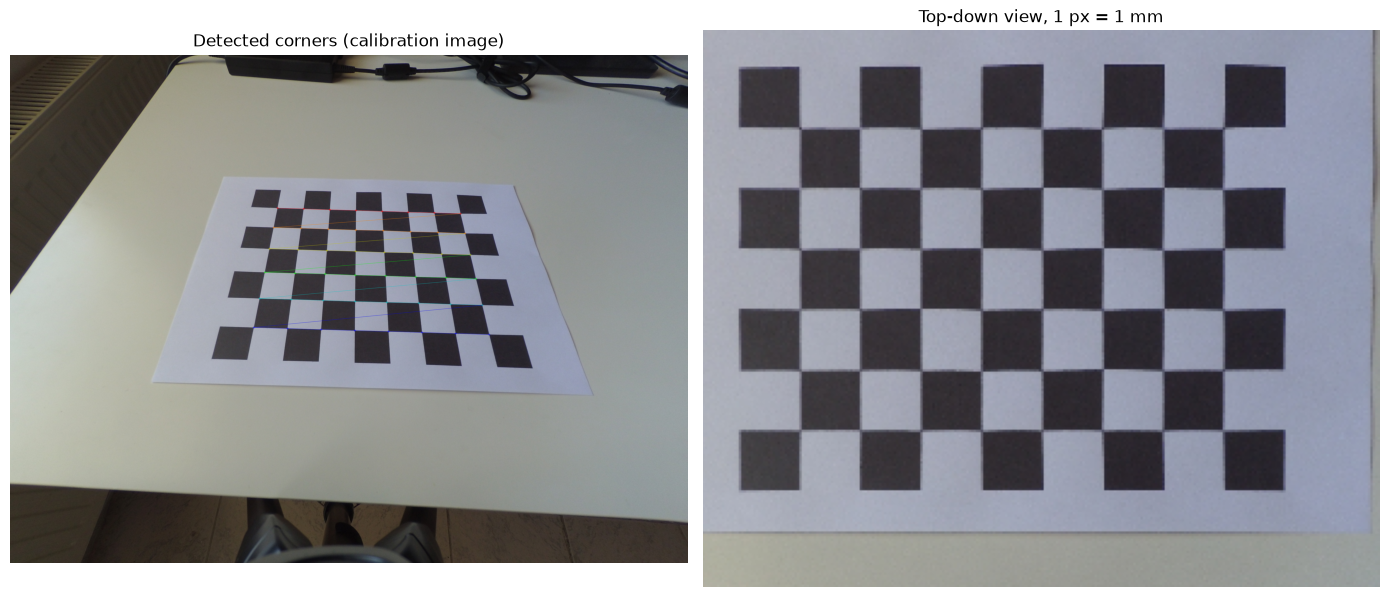

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "frame_4.jpg"          # image WITH the checkerboard visible
CALIBRATION_OUT = "plane_calibration.npz"

# Board spec: 8x6 SQUARES, 25 mm each. OpenCV wants INNER corners (squares - 1).
SQUARES_X, SQUARES_Y = 9, 7
SQUARE_SIZE_MM = 25.0
PATTERN_SIZE = (SQUARES_X - 1, SQUARES_Y - 1)  # (7, 5)
MARGIN_MM = 40  # extra border in the top-down output so nearby objects aren't clipped

# --- Load image ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# --- Detect chessboard inner corners ---
ret, corners = cv2.findChessboardCorners(
    gray, PATTERN_SIZE,
    flags=cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE
)
if not ret:
    raise RuntimeError(
        f"Chessboard {PATTERN_SIZE} not found. Check SQUARES_X/SQUARES_Y "
        f"match the physical board, and that it's fully visible/unoccluded."
    )

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)

# --- Real-world (mm) coordinates for each inner corner, z=0 plane ---
objp = np.zeros((PATTERN_SIZE[0] * PATTERN_SIZE[1], 2), dtype=np.float32)
objp[:, :2] = np.mgrid[0:PATTERN_SIZE[0], 0:PATTERN_SIZE[1]].T.reshape(-1, 2) * SQUARE_SIZE_MM
img_points = corners.reshape(-1, 2)

# --- Homography: image pixels <-> board-plane mm coordinates ---
H, mask = cv2.findHomography(img_points, objp, method=0)

reprojected = cv2.perspectiveTransform(objp.reshape(-1, 1, 2), np.linalg.inv(H)).reshape(-1, 2)
reproj_error = np.linalg.norm(reprojected - img_points, axis=1).mean()
print(f"Mean reprojection error: {reproj_error:.3f} px")

# --- Top-down canvas size (shared by every image this calibration is applied to) ---
board_w_mm = (SQUARES_X - 1) * SQUARE_SIZE_MM
board_h_mm = (SQUARES_Y - 1) * SQUARE_SIZE_MM
out_w = int(board_w_mm + 2 * MARGIN_MM)
out_h = int(board_h_mm + 2 * MARGIN_MM)

shift = np.array([
    [1, 0, MARGIN_MM],
    [0, 1, MARGIN_MM],
    [0, 0, 1]
], dtype=np.float64)
H_topdown = shift @ H  # image pixels -> shifted mm plane, ready for warpPerspective

# --- IMPORTANT: this calibration is only valid as long as the camera and the
# plane (table height) don't move relative to each other. If you move the
# camera or the surface, you need to re-run this against a new pattern shot. ---
np.savez(
    CALIBRATION_OUT,
    H=H,
    H_topdown=H_topdown,
    out_w=out_w,
    out_h=out_h,
    square_size_mm=SQUARE_SIZE_MM,
    margin_mm=MARGIN_MM,
    reproj_error=reproj_error,
)
print(f"Saved calibration to {CALIBRATION_OUT}")

# --- Visualize the calibration image + its top-down warp, as a sanity check ---
vis = img.copy()
cv2.drawChessboardCorners(vis, PATTERN_SIZE, corners, ret)
warped = cv2.warpPerspective(img, H_topdown, (out_w, out_h))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
axes[0].set_title("Detected corners (calibration image)")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
axes[1].set_title("Top-down view, 1 px = 1 mm")
axes[1].axis("off")
plt.tight_layout()
plt.show()

Loaded calibration (reprojection error was 0.531 px)


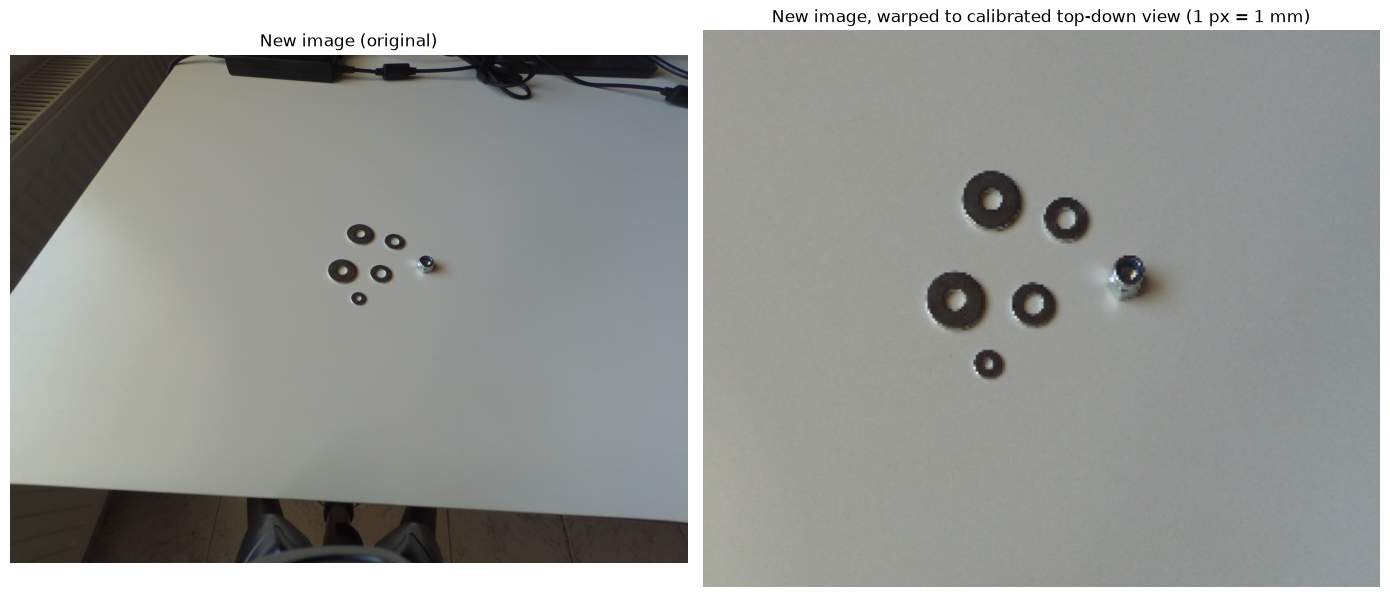

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "frame_5.jpg"          # image WITHOUT the checkerboard, same camera/pose
CALIBRATION_IN = "plane_calibration.npz"

# --- Load the saved calibration (computed once from the checkerboard image) ---
calib = np.load(CALIBRATION_IN)
H = calib["H"]
H_topdown = calib["H_topdown"]
out_w = int(calib["out_w"])
out_h = int(calib["out_h"])
square_size_mm = float(calib["square_size_mm"])
margin_mm = float(calib["margin_mm"])

print(f"Loaded calibration (reprojection error was {float(calib['reproj_error']):.3f} px)")

# --- Load the new image (camera and plane must be unchanged since calibration) ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")


def pixel_to_mm(u, v):
    """Convert an image pixel coordinate to real-world mm on the calibrated plane."""
    pt = np.array([u, v, 1.0])
    mm = H @ pt
    mm /= mm[2]
    return mm[0], mm[1]


def mm_to_pixel(x_mm, y_mm):
    """Convert a real-world mm coordinate on the plane back to image pixels."""
    H_inv = np.linalg.inv(H)
    pt = np.array([x_mm, y_mm, 1.0])
    px = H_inv @ pt
    px /= px[2]
    return px[0], px[1]


# --- Warp the new image to the same top-down metric view as the calibration ---
warped = cv2.warpPerspective(img, H_topdown, (out_w, out_h))

# --- Visualize ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("New image (original)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
axes[1].set_title("New image, warped to calibrated top-down view (1 px = 1 mm)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Example: convert a pixel point from the new image into real-world mm
# x_mm, y_mm = pixel_to_mm(1200, 800)
# print(f"That pixel is at ({x_mm:.1f}, {y_mm:.1f}) mm on the board plane")

Loaded calibration (reprojection error was 0.531 px)
Saved top-down image to frame_5_fixed.png


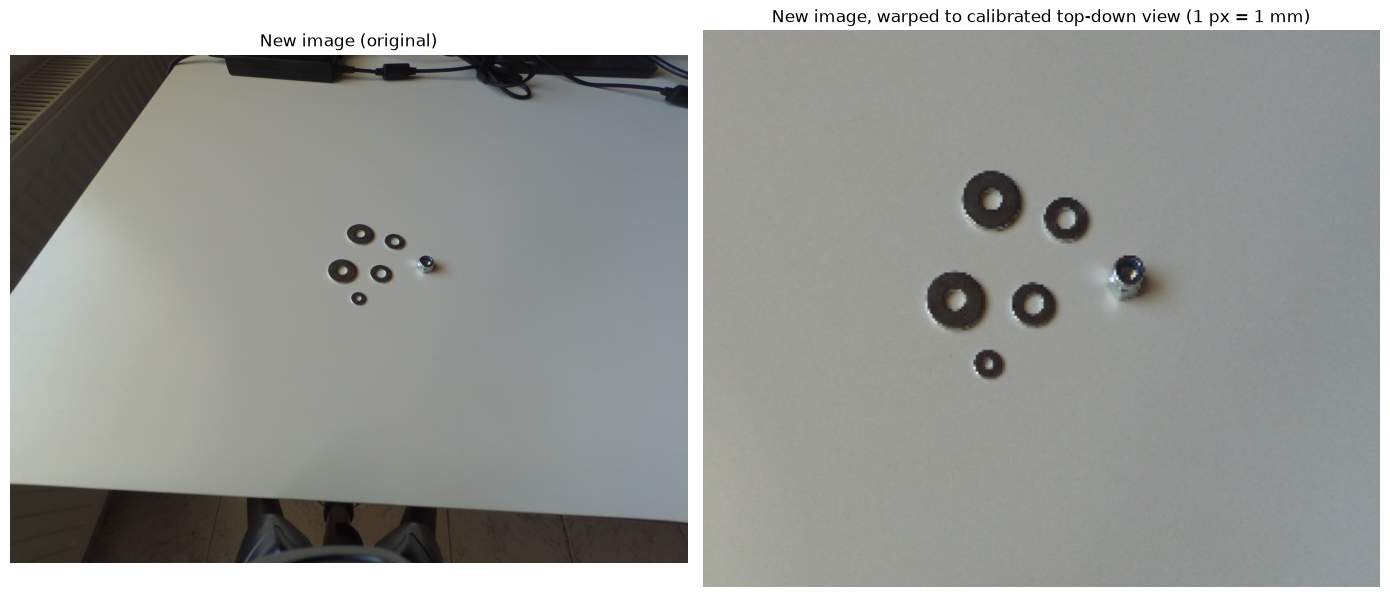

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "frame_5.jpg"          # image WITHOUT the checkerboard, same camera/pose
CALIBRATION_IN = "plane_calibration.npz"
WARPED_OUT = "frame_5_fixed.png"  # where to save the rectified top-down result

# --- Load the saved calibration (computed once from the checkerboard image) ---
calib = np.load(CALIBRATION_IN)
H = calib["H"]
H_topdown = calib["H_topdown"]
out_w = int(calib["out_w"])
out_h = int(calib["out_h"])
square_size_mm = float(calib["square_size_mm"])
margin_mm = float(calib["margin_mm"])

print(f"Loaded calibration (reprojection error was {float(calib['reproj_error']):.3f} px)")

# --- Load the new image (camera and plane must be unchanged since calibration) ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")


def pixel_to_mm(u, v):
    """Convert an image pixel coordinate to real-world mm on the calibrated plane."""
    pt = np.array([u, v, 1.0])
    mm = H @ pt
    mm /= mm[2]
    return mm[0], mm[1]


def mm_to_pixel(x_mm, y_mm):
    """Convert a real-world mm coordinate on the plane back to image pixels."""
    H_inv = np.linalg.inv(H)
    pt = np.array([x_mm, y_mm, 1.0])
    px = H_inv @ pt
    px /= px[2]
    return px[0], px[1]


# --- Warp the new image to the same top-down metric view as the calibration ---
warped = cv2.warpPerspective(img, H_topdown, (out_w, out_h))

# --- Save the warped result to disk ---
cv2.imwrite(WARPED_OUT, warped)
print(f"Saved top-down image to {WARPED_OUT}")

# --- Visualize ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("New image (original)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
axes[1].set_title("New image, warped to calibrated top-down view (1 px = 1 mm)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Example: convert a pixel point from the new image into real-world mm
# x_mm, y_mm = pixel_to_mm(1200, 800)
# print(f"That pixel is at ({x_mm:.1f}, {y_mm:.1f}) mm on the board plane")